# Wykonywanie prostych metod numerycznych z uzyciem modulu Scipy

### import pakietow i ich modulow oraz opis podstawowych operacji numerycznych

In [363]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import linalg
from scipy import optimize
from scipy import integrate
from scipy import special

In [364]:
help(linalg.solve)

Help on function solve in module scipy.linalg.basic:

solve(a, b, sym_pos=False, lower=False, overwrite_a=False, overwrite_b=False, debug=None, check_finite=True, assume_a='gen', transposed=False)
    Solves the linear equation set ``a * x = b`` for the unknown ``x``
    for square ``a`` matrix.
    
    If the data matrix is known to be a particular type then supplying the
    corresponding string to ``assume_a`` key chooses the dedicated solver.
    The available options are
    
    ===================  ========
     generic matrix       'gen'
     symmetric            'sym'
     hermitian            'her'
     positive definite    'pos'
    ===================  ========
    
    If omitted, ``'gen'`` is the default structure.
    
    The datatype of the arrays define which solver is called regardless
    of the values. In other words, even when the complex array entries have
    precisely zero imaginary parts, the complex solver will be called based
    on the data type of the arr

In [365]:
help(optimize.root_scalar)

Help on function root_scalar in module scipy.optimize._root_scalar:

root_scalar(f, args=(), method=None, bracket=None, fprime=None, fprime2=None, x0=None, x1=None, xtol=None, rtol=None, maxiter=None, options=None)
    Find a root of a scalar function.
    
    Parameters
    ----------
    f : callable
        A function to find a root of.
    args : tuple, optional
        Extra arguments passed to the objective function and its derivative(s).
    method : str, optional
        Type of solver.  Should be one of
    
            - 'bisect'    :ref:`(see here) <optimize.root_scalar-bisect>`
            - 'brentq'    :ref:`(see here) <optimize.root_scalar-brentq>`
            - 'brenth'    :ref:`(see here) <optimize.root_scalar-brenth>`
            - 'ridder'    :ref:`(see here) <optimize.root_scalar-ridder>`
            - 'toms748'    :ref:`(see here) <optimize.root_scalar-toms748>`
            - 'newton'    :ref:`(see here) <optimize.root_scalar-newton>`
            - 'secant'    :ref

In [366]:
help(integrate.quad)

Help on function quad in module scipy.integrate.quadpack:

quad(func, a, b, args=(), full_output=0, epsabs=1.49e-08, epsrel=1.49e-08, limit=50, points=None, weight=None, wvar=None, wopts=None, maxp1=50, limlst=50)
    Compute a definite integral.
    
    Integrate func from `a` to `b` (possibly infinite interval) using a
    technique from the Fortran library QUADPACK.
    
    Parameters
    ----------
    func : {function, scipy.LowLevelCallable}
        A Python function or method to integrate. If `func` takes many
        arguments, it is integrated along the axis corresponding to the
        first argument.
    
        If the user desires improved integration performance, then `f` may
        be a `scipy.LowLevelCallable` with one of the signatures::
    
            double func(double x)
            double func(double x, void *user_data)
            double func(int n, double *xx)
            double func(int n, double *xx, void *user_data)
    
        The ``user_data`` is the d

In [367]:
help(special)

Help on package scipy.special in scipy:

NAME
    scipy.special

DESCRIPTION
    Special functions (:mod:`scipy.special`)
    
    .. currentmodule:: scipy.special
    
    Nearly all of the functions below are universal functions and follow
    broadcasting and automatic array-looping rules.
    
    .. seealso::
    
       `scipy.special.cython_special` -- Typed Cython versions of special functions
    
    
    Error handling
    
    Errors are handled by returning NaNs or other appropriate values.
    Some of the special function routines can emit warnings or raise
    exceptions when an error occurs. By default this is disabled; to
    query and control the current error handling state the following
    functions are provided.
    
    .. autosummary::
       :toctree: generated/
    
       geterr                 -- Get the current way of handling special-function errors.
       seterr                 -- Set how special-function errors are handled.
       errstate              

### Przyklad  rozwiazywania ukladu rownan liniowych
>  A*x == b

#### tworzy tablice-macierz 3x3

In [368]:
A = np.array([[3., 2., 0.], [1., -1., 0.], [0., 5., 1.]])

#### tworzy tablice-wektor trojskladnikowy

In [369]:
b = np.array([2, 4, -1], float)

 #### rozwiazuje uklad rownan liniowych w dziedzinie rzeczywistej

In [370]:
x = linalg.solve(A, b)
print("x =", x)

x = [ 2. -2.  9.]


### Przyklad optymalizacji funkcji _f_(_x_) poprzez rozwiazywanie rownania nieliniowego
> f(x) == 0

#### definiuje wzor funkcji

In [371]:
def f(x):
    return (x**3 - 1)

#### definiuje pochodna funkcji

In [372]:
def fp(x):
    return 3*x**2

#### stosuje metode stycznych Newtona z punktem startowym

In [373]:
x = optimize.root_scalar(f, x0=0.2, fprime=fp, method='newton')
print("xroot =", x.root)

xroot = 1.0


### Przyklad obliczania calki oznaczonej

#### liczy numerycznie calke oznaczona w przedziale (0,4.5) z podanej w lambdzie funkcji matematycznej

In [374]:
I = integrate.quad(lambda x: np.sin(3*np.cos(x)+5), 0, np.pi)

#### zwraca wartosc przyblizona i blad metody

In [375]:
print("I =", I) # rezultat typu tuple

I = (0.7834193754355544, 2.8159210376143092e-14)


### Przyklad obliczania niewlasciwej calki oznaczonej

#### definiuje wzor w funkcji globalnej

In [376]:
def fun(x):
    return np.exp(-x**2)

#### liczy calke z funkcji w granicach od minus do plus nieskonczonosci

In [377]:
I = integrate.quad(fun, -np.inf, np.inf)

#### zwraca jedynie wartosc przyblizona

In [378]:
print("I =", I[0])

I = 1.7724538509055159


#### liczy wartosc dokladna calki

In [379]:
print("sqrt(pi) =", np.sqrt(np.pi) )

sqrt(pi) = 1.7724538509055159


### Przyklad ewaluacji funkcji specjalnych

#### tablicuje wartosci [sferycznej funkcji Bessela](https://en.wikipedia.org/wiki/Bessel_function) zerowego rzedu

In [380]:
x = np.linspace(-10.0, 10.0, 1000)
y = special.spherical_jn(0,x)

#### wyswietla wykres sferycznej funkcji Bessela zerowego rzedu

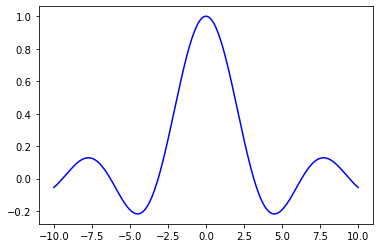

In [381]:
fig, axs = plt.subplots()
axs.plot(x, y, color='blue', linestyle='solid')

#### tablicuje wartosci [funkcji sinc](https://en.wikipedia.org/wiki/Sinc_function)

In [382]:
X = np.arange(-10.0, 10.5, 0.5)
print("X =", X)
Y = np.array( [ (np.sin(v)/v if v!=0.0 else 1.0) for v in X ] )
print("Y =", Y)

X = [-10.   -9.5  -9.   -8.5  -8.   -7.5  -7.   -6.5  -6.   -5.5  -5.   -4.5
  -4.   -3.5  -3.   -2.5  -2.   -1.5  -1.   -0.5   0.    0.5   1.    1.5
   2.    2.5   3.    3.5   4.    4.5   5.    5.5   6.    6.5   7.    7.5
   8.    8.5   9.    9.5  10. ]
Y = [-0.05440211 -0.00791064  0.04579094  0.09393966  0.12366978  0.12506666
  0.09385523  0.03309538 -0.04656925 -0.12828006 -0.19178485 -0.21722892
 -0.18920062 -0.10022378  0.04704     0.23938886  0.45464871  0.66499666
  0.84147098  0.95885108  1.          0.95885108  0.84147098  0.66499666
  0.45464871  0.23938886  0.04704    -0.10022378 -0.18920062 -0.21722892
 -0.19178485 -0.12828006 -0.04656925  0.03309538  0.09385523  0.12506666
  0.12366978  0.09393966  0.04579094 -0.00791064 -0.05440211]


#### nanosi na wykres funkcji Bessela punkty funkcji sinc

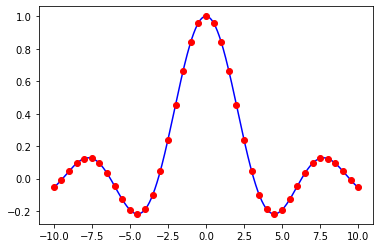

In [383]:
axs.plot(X, Y, color='red', linestyle='none', marker='o')
display(fig)